# Introduction

The COVID-19 pandemic created a large amount of health-related data that can
be analyzed to understand the spread and impact of the disease over time.

This project focuses on analyzing COVID-19 data from different states and
union territories of India using Python. The dataset contains information
such as dates, total confirmed cases, deaths, recovered cases, new cases,
new deaths, new recoveries, and geographical coordinates.

The main purpose of this project is to explore the dataset, identify
important patterns and trends, compare COVID-19 outcomes across states and
union territories, and understand relationships between different
COVID-19 indicators.

The analysis uses Python libraries such as NumPy, Pandas, Matplotlib and
Seaborn. Various techniques including data cleaning, feature engineering,
exploratory data analysis, time-series analysis, state-wise comparison,
geographic analysis, statistical analysis, correlation analysis and
visualization are applied throughout the project.

This project demonstrates how raw real-world data can be processed,
analyzed and visualized to generate meaningful data-driven insights.

# Objectives

The main objectives of this project are:

1. To understand and preprocess the COVID-19 dataset.
2. To perform exploratory data analysis on COVID-19 cases in India.
3. To analyze the change in COVID-19 cases over time.
4. To compare confirmed cases, deaths, recoveries and active cases across
   states and union territories.
5. To examine the geographical distribution of COVID-19 cases.
6. To identify statistical patterns, variations and potential outliers.
7. To analyze relationships between COVID-19 indicators using correlation
   analysis.
8. To create meaningful visualizations for better interpretation of the data.
9. To derive data-driven insights from the analysis.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv(r"C:\Users\Satyaki Banerjee\Downloads\covid.csv")

In [8]:
df.head()

,Date,Name of State / UT,Latitude,Longitude,Total Confirmed cases,Death,Cured/Discharged/Migrated,New cases,New deaths,New recovered
0,2020-01-30,Kerala,10.8505,76.2711,1.0,0,0.0,0,0,0
1,2020-01-31,Kerala,10.8505,76.2711,1.0,0,0.0,0,0,0
2,2020-02-01,Kerala,10.8505,76.2711,2.0,0,0.0,1,0,0
3,2020-02-02,Kerala,10.8505,76.2711,3.0,0,0.0,1,0,0
4,2020-02-03,Kerala,10.8505,76.2711,3.0,0,0.0,0,0,0


In [9]:
df.shape


(4692, 10)

In [10]:
df.columns

Index(['Date', 'Name of State / UT', 'Latitude', 'Longitude',
       'Total Confirmed cases', 'Death', 'Cured/Discharged/Migrated',
       'New cases', 'New deaths', 'New recovered'],
      dtype='str')

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4692 entries, 0 to 4691
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       4692 non-null   str    
 1   Name of State / UT         4692 non-null   str    
 2   Latitude                   4692 non-null   float64
 3   Longitude                  4692 non-null   float64
 4   Total Confirmed cases      4692 non-null   float64
 5   Death                      4692 non-null   str    
 6   Cured/Discharged/Migrated  4692 non-null   float64
 7   New cases                  4692 non-null   int64  
 8   New deaths                 4692 non-null   int64  
 9   New recovered              4692 non-null   int64  
dtypes: float64(4), int64(3), str(3)
memory usage: 366.7 KB


In [12]:
df.describe()

,Latitude,Longitude,Total Confirmed cases,Cured/Discharged/Migrated,New cases,New deaths,New recovered
count,4692.000000,4692.000000,4692.000000,4692.000000,4692.000000,4692.0,4692.000000
mean,23.185327,81.451837,11393.925192,6908.130648,418.643009,0.0,283.069054
std,6.635913,6.959475,37208.600846,23390.671258,1259.748923,0.0,947.925811
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.0,-1.000000
25%,18.112400,76.271100,39.000000,9.000000,1.000000,0.0,0.000000
50%,23.940800,79.019300,619.000000,197.500000,26.000000,0.0,8.000000
75%,28.218000,85.313100,5233.000000,2736.000000,210.250000,0.0,119.000000
max,34.299600,94.727800,468265.000000,305521.000000,18366.000000,0.0,13401.000000


In [13]:
df.isnull().sum()

Date                         0
Name of State / UT           0
Latitude                     0
Longitude                    0
Total Confirmed cases        0
Death                        0
Cured/Discharged/Migrated    0
New cases                    0
New deaths                   0
New recovered                0
dtype: int64

In [71]:
df["Death"] = pd.to_numeric(df["Death"],errors ="coerce")
df["Death_Rate"] = ( df["New deaths"] / df["Total Confirmed cases"]) * 100

In [74]:
df["Recovery_Rate"] = ( df["Cured/Discharged/Migrated"] / df["Total Confirmed cases"]) * 100

df["Death_Rate"] = np.where(
    df["Total Confirmed cases"] > 0,
    (df["Death"] / df["Total Confirmed cases"]) * 100,
    np.nan
)

df["Recovery_Rate"] = np.where(
    df["Total Confirmed cases"] > 0,
    (df["Cured/Discharged/Migrated"]/
    df["Total Confirmed cases"]) * 100,
    np.nan
)

In [18]:
#Time series analysis
df["Date"] = pd.to_datetime(df["Date"])

In [20]:
daily_cases = df.groupby("Date")["Total Confirmed cases"].sum()

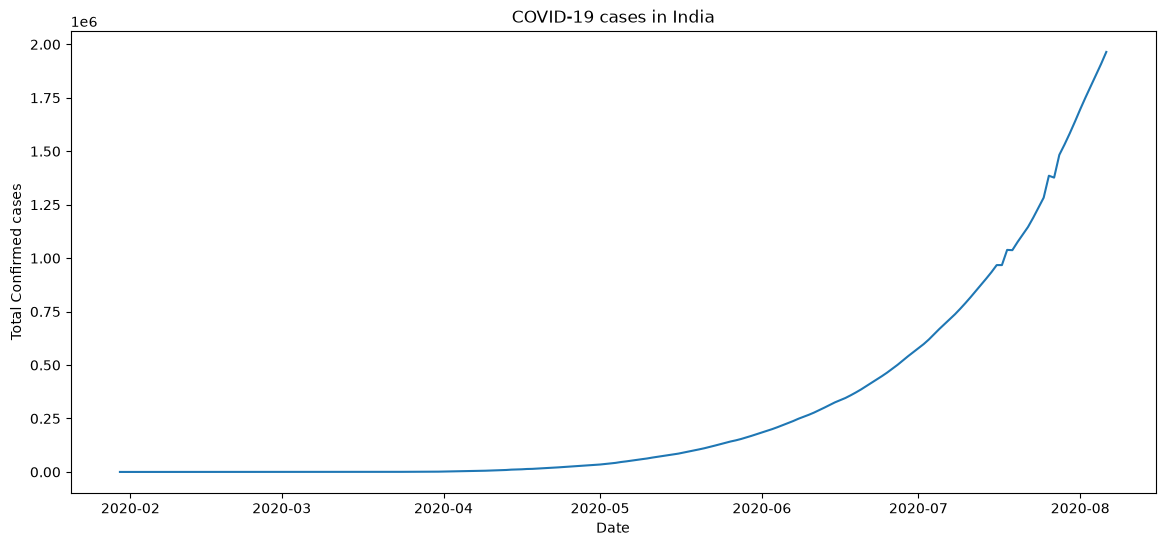

In [22]:
plt.figure( figsize = (14,6))
plt.plot(daily_cases)
plt.xlabel("Date")
plt.ylabel("Total Confirmed cases")
plt.title("COVID-19 cases in India")
plt.show()

In [24]:
#State Analysis
state_cases = (
    df.groupby("Name of State / UT")["Total Confirmed cases"].max().sort_values(ascending = False)
)

In [25]:
state_deaths = (
    df.groupby("Name of State / UT")["New deaths"].max().sort_values(ascending = False)
)

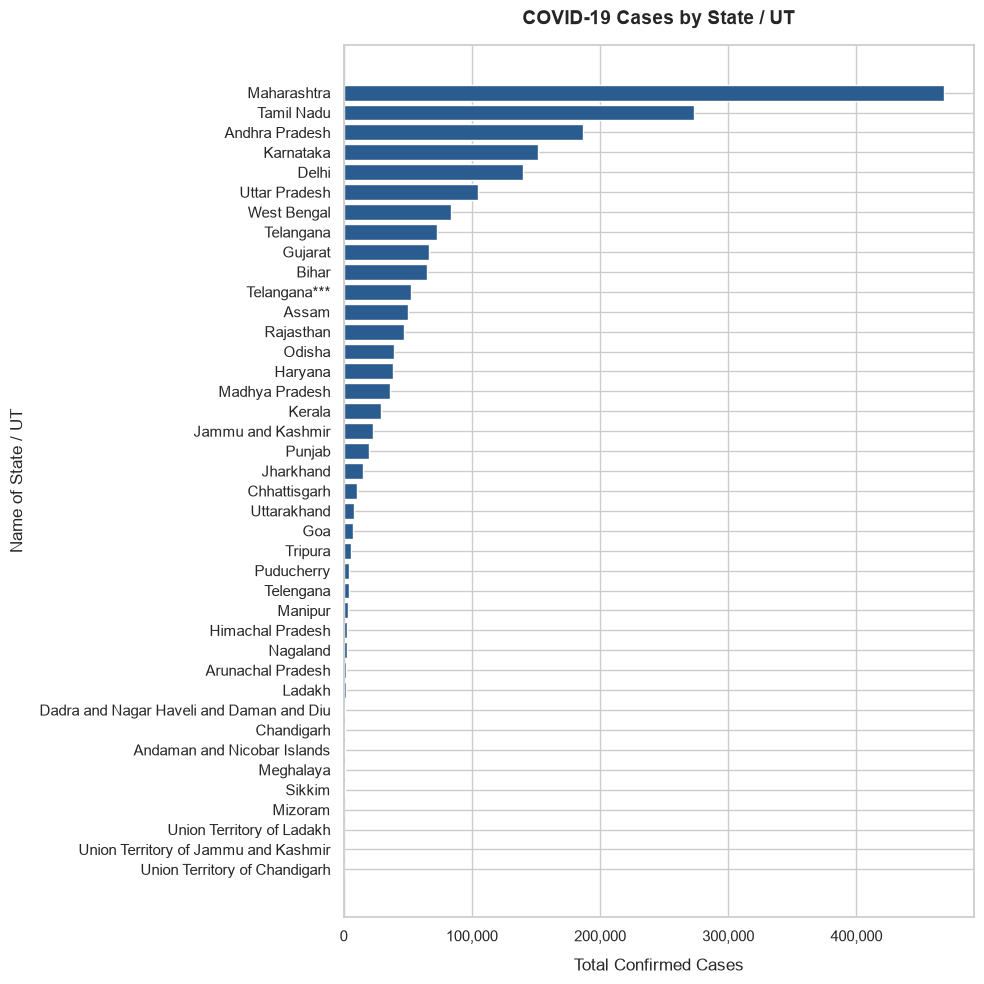

In [35]:
sns.set_theme(style = "whitegrid")
plt.figure(figsize = (10,10))
sorted_cases = state_cases.sort_values(ascending = True)
plt.barh(sorted_cases.index , sorted_cases.values , color = "#2b5c8f")

plt.xlabel("Total Confirmed Cases" , fontsize = 12 , labelpad = 10)
plt.ylabel("Name of State / UT" , fontsize = 12 , labelpad = 10)
plt.title("COVID-19 Cases by State / UT" , fontsize = 14 , fontweight = "bold" , pad = 15)

plt.gca().xaxis.set_major_formatter("{x:,.0f}")

plt.tight_layout()
plt.show()

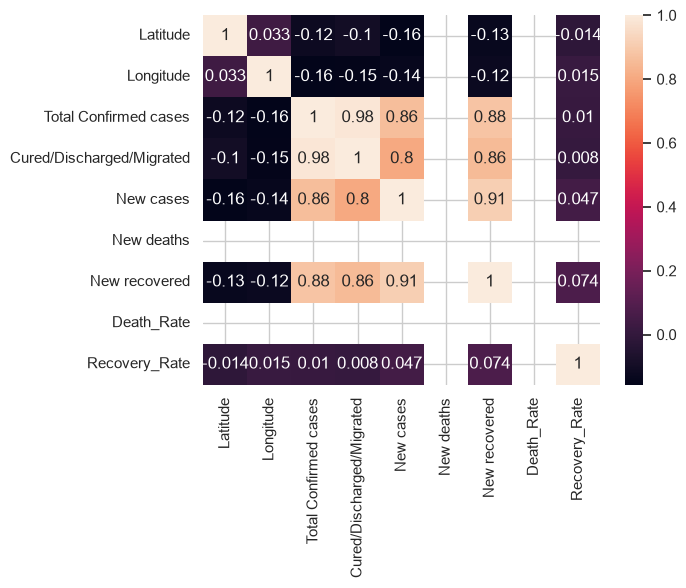

In [38]:
sns.heatmap(
    df.corr(numeric_only = True),
    annot = True
)

plt.show()

In [39]:
#Advanced Analysis
daily_cases = (
    df.groupby("Date")["Total Confirmed cases"].sum().sort_index()
)

In [40]:
daily_cases_7day = daily_cases.rolling(window = 7).mean()

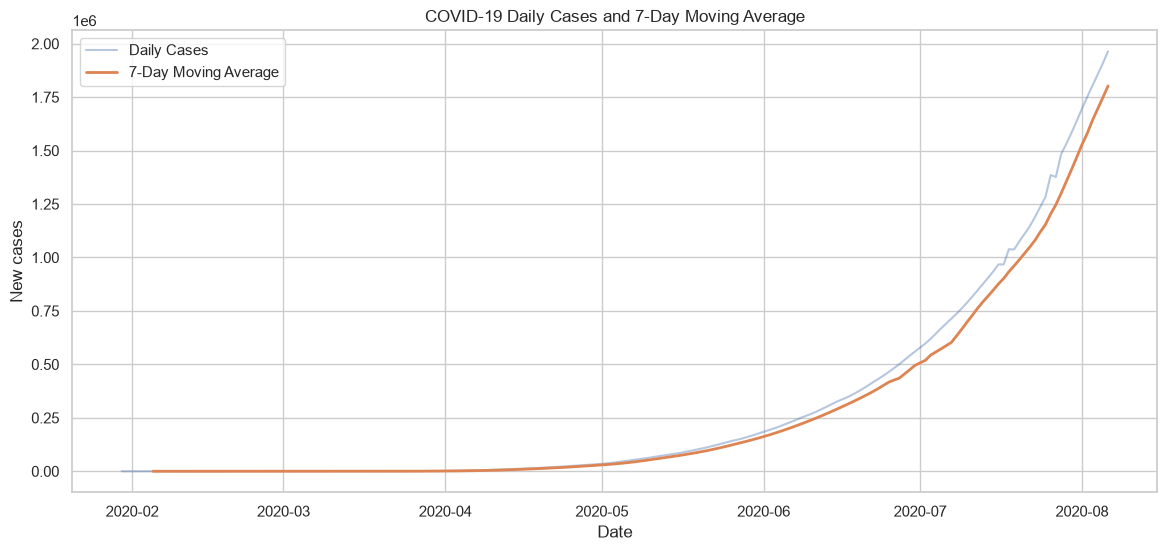

In [43]:
plt.figure(figsize = (14,6))

plt.plot(
    daily_cases,
    alpha = 0.4,
    label = "Daily Cases"
)

plt.plot(
    daily_cases_7day,
    linewidth = 2,
    label = "7-Day Moving Average"
)

plt.xlabel("Date")
plt.ylabel("New cases")
plt.title("COVID-19 Daily Cases and 7-Day Moving Average")
plt.legend()

plt.show()

In [45]:
daily_cases_30day = daily_cases.rolling(30).mean()

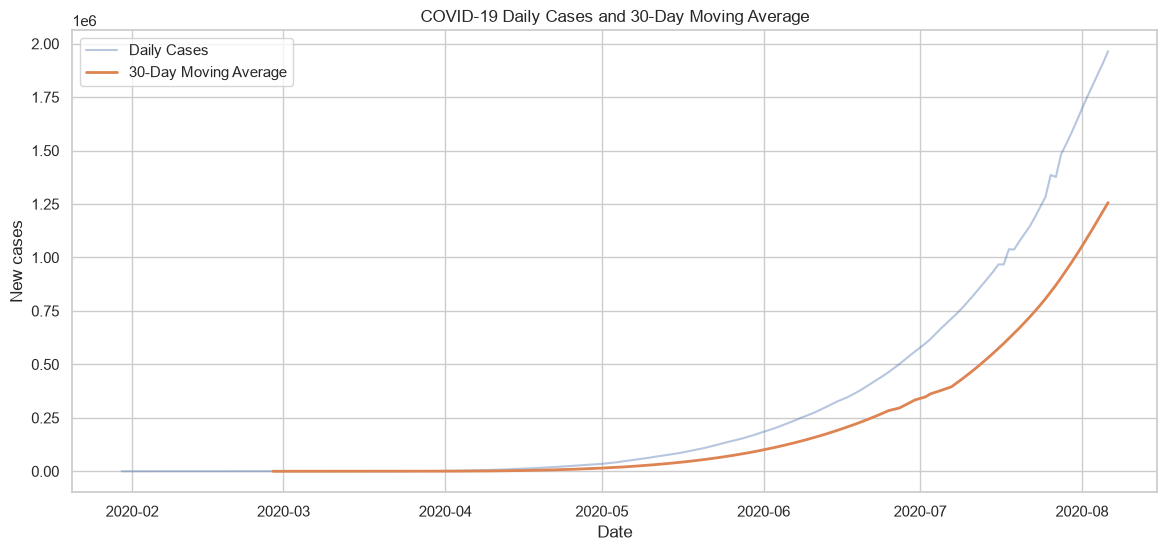

In [46]:
plt.figure(figsize = (14,6))

plt.plot(
    daily_cases,
    alpha = 0.4,
    label = "Daily Cases"
)

plt.plot(
    daily_cases_30day,
    linewidth = 2,
    label = "30-Day Moving Average"
)

plt.xlabel("Date")
plt.ylabel("New cases")
plt.title("COVID-19 Daily Cases and 30-Day Moving Average")
plt.legend()

plt.show()

In [47]:
daily_growth = daily_cases.pct_change() * 100

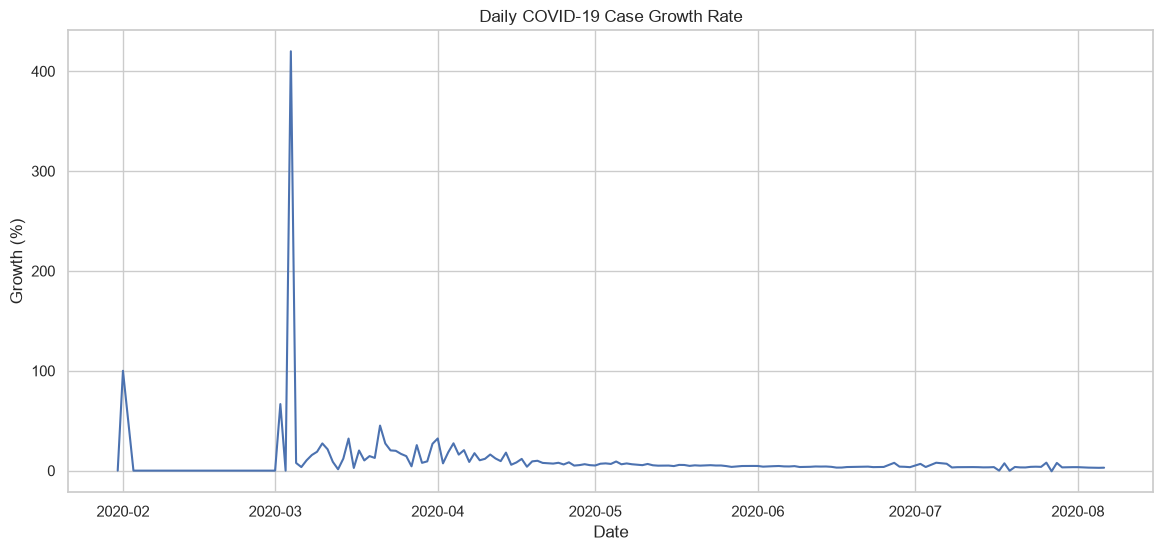

In [48]:
plt.figure(figsize = (14,6))

plt.plot(daily_growth)

plt.xlabel("Date")
plt.ylabel("Growth (%)")
plt.title("Daily COVID-19 Case Growth Rate")

plt.show()

In [51]:
rolling_cases = daily_cases.rolling(7).mean()

In [52]:
peak_date = rolling_cases.idxmax()
peak_value = rolling_cases.max()

print("Peak Date:",peak_date)
print("Peak 7-Day Average:",peak_value)

Peak Date: 2020-08-06 00:00:00
Peak 7-Day Average: 1802544.4285714286


In [54]:
largest_increase_date = daily_new_cases.idxmax()

print(largest_increase_date)
print(daily_new_cases.max())

2020-07-28 00:00:00
106421.0


Task was destroyed but it is pending!
task: <Task pending name='Task-198' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\Satyaki Banerjee\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-199' coro=<Kernel.shell_main() running at C:\Users\Satyaki Banerjee\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\Satyaki Banerjee\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>


C:\Users\Satyaki Banerjee\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\text.py:543: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  xmin, xmax = min(xs), max(xs)
Task was destroyed but it is pending!
task: <Task pending name='Task-199' coro=<Kernel.shell_main() running at C:\Users\Satyaki Banerjee\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


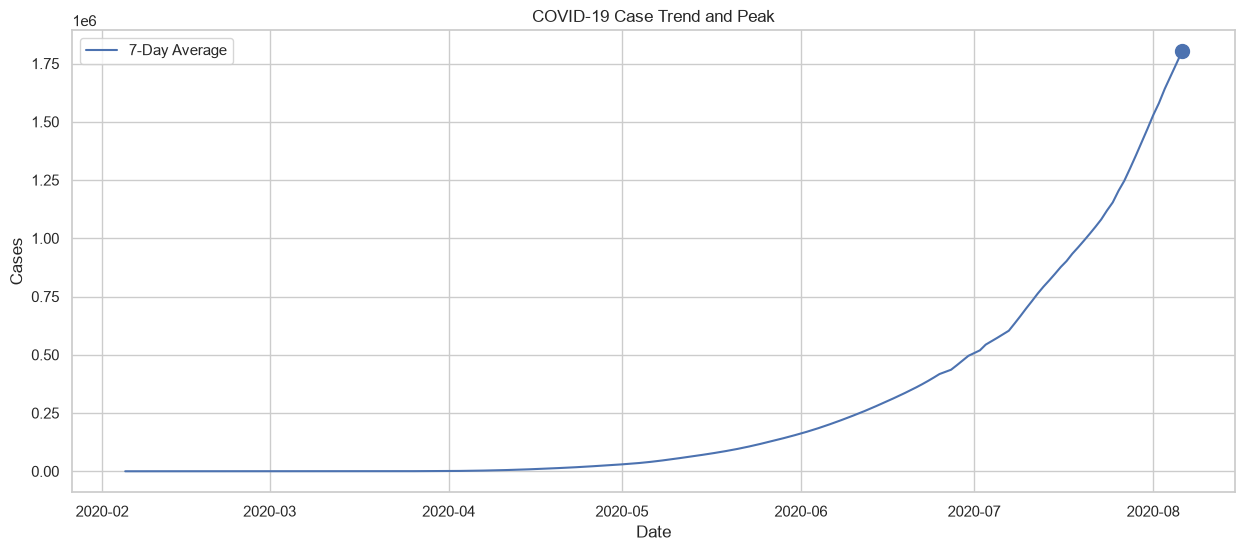

In [55]:
plt.figure(figsize = (15,6))

plt.plot(
    rolling_cases,
    label = "7-Day Average"
)

plt.scatter(
    peak_date,
    peak_value,
    s = 100
)

plt.xlabel("Date")
plt.ylabel("Cases")
plt.title("COVID-19 Case Trend and Peak")
plt.legend()

plt.show()
    

In [59]:
#IQR
Q1 = df["Total Confirmed cases"].quantile(0.25)
Q3 = df["Total Confirmed cases"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [60]:
outliers = df[
    (df["Total Confirmed cases"] < lower_bound) | (df["Total Confirmed cases"] > upper_bound)
    ]

In [61]:
outliers.head()

,Date,Name of State / UT,Latitude,Longitude,Total Confirmed cases,Death,Cured/Discharged/Migrated,New cases,New deaths,New recovered,Death_Rate,Recovery_Rate
1609,2020-05-05,Maharashtra,19.7515,75.7139,14541.0,583,2465.0,1567,0,350,0.0,2.406987
1642,2020-05-06,Maharashtra,19.7515,75.7139,15525.0,617,2819.0,984,0,354,0.0,2.280193
1675,2020-05-07,Maharashtra,19.7515,75.7139,16758.0,651,3094.0,1233,0,275,0.0,1.641007
1708,2020-05-08,Maharashtra,19.7515,75.7139,17974.0,694,3301.0,1216,0,207,0.0,1.151664
1741,2020-05-09,Maharashtra,19.7515,75.7139,19063.0,731,3470.0,1089,0,169,0.0,0.886534


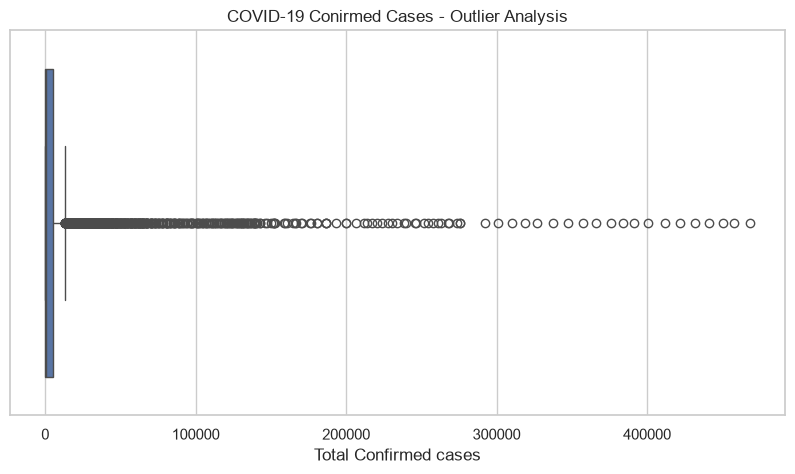

In [62]:
plt.figure( figsize = (10,5))

sns.boxplot(
    x = df["Total Confirmed cases"]
)

plt.title("COVID-19 Conirmed Cases - Outlier Analysis")

plt.show()

In [63]:
correlation = df[
    [
        "Total Confirmed cases",
        "New deaths",
        "New recovered"
    ]
].corr()

print(correlation)

                       Total Confirmed cases  New deaths  New recovered
Total Confirmed cases               1.000000         NaN       0.879001
New deaths                               NaN         NaN            NaN
New recovered                       0.879001         NaN       1.000000


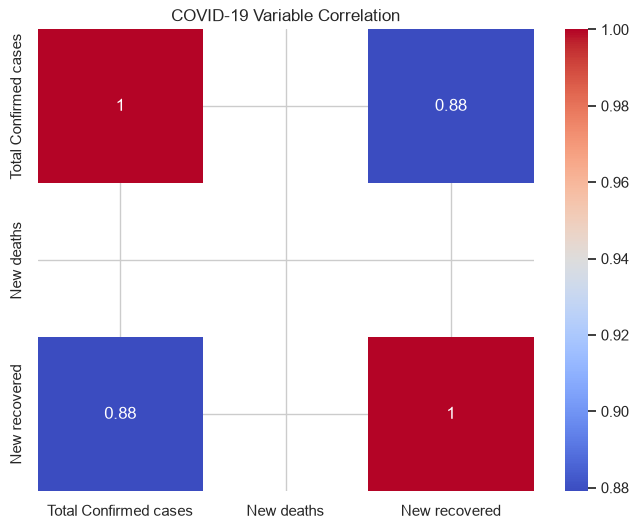

In [64]:
plt.figure(figsize = (8,6))

sns.heatmap(
    correlation,
    annot = True,
    cmap = "coolwarm"
)

plt.title("COVID-19 Variable Correlation")

plt.show()

In [65]:
#CFR
df["CFR"] = (
    df["New deaths"] / df["Total Confirmed cases"]
) * 100

In [66]:
df["CFR"] = np.where(
    df["Total Confirmed cases"] > 0,
    (df["New deaths"] / df["Total Confirmed cases"]) * 100,
    np.nan
)
    

In [67]:
df["CFR"].describe()

count    4692.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: CFR, dtype: float64

In [68]:
df["Day_Name"] = df["Date"].dt.day_name()

In [69]:
day_analysis = (
    df.groupby("Day_Name")["Total Confirmed cases"].sum()
)

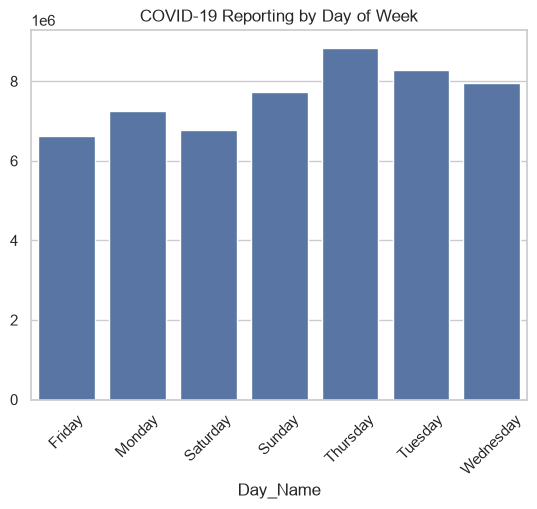

In [70]:
sns.barplot(
    x = day_analysis.index,
    y = day_analysis.values
)

plt.xticks(rotation = 45)
plt.title("COVID-19 Reporting by Day of Week")

plt.show()

In [75]:
#State wise analysis
df["Name of State / UT"].nunique()

40

In [76]:
df["Name of State / UT"].unique()

<StringArray>
[                                  'Kerala',
                                    'Delhi',
                                'Telengana',
                                  'Haryana',
                                'Rajasthan',
                            'Uttar Pradesh',
                               'Tamil Nadu',
                'Union Territory of Ladakh',
                                'Karnataka',
                              'Maharashtra',
                                   'Punjab',
     'Union Territory of Jammu and Kashmir',
                           'Andhra Pradesh',
                              'Uttarakhand',
                                   'Odisha',
                               'Puducherry',
                              'West Bengal',
                             'Chhattisgarh',
            'Union Territory of Chandigarh',
                                  'Gujarat',
                               'Chandigarh',
                         'Himachal Prades

In [77]:
df["Date"].max()


Timestamp('2020-08-06 00:00:00')

In [78]:
latest_date = df["Date"].max()

latest_data = df[
    df["Date"] == latest_date
].copy()

In [79]:
latest_data.head()

,Date,Name of State / UT,Latitude,Longitude,Total Confirmed cases,Death,Cured/Discharged/Migrated,New cases,New deaths,New recovered,Death_Rate,Recovery_Rate,CFR,Day_Name
4657,2020-08-06,Andaman and Nicobar Islands,11.7401,92.6586,1027.0,14.0,326.0,99,0,49,1.363194,31.742941,0.0,Thursday
4658,2020-08-06,Andhra Pradesh,15.9129,79.7400,186461.0,1681.0,104354.0,10128,0,8729,0.901529,55.965591,0.0,Thursday
4659,2020-08-06,Arunachal Pradesh,28.2180,94.7278,1855.0,3.0,1210.0,65,0,105,0.161725,65.229111,0.0,Thursday
4660,2020-08-06,Assam,26.2006,92.9376,50445.0,121.0,35892.0,2284,0,1471,0.239865,71.150758,0.0,Thursday
4661,2020-08-06,Bihar,25.0961,85.3131,64770.0,355.0,42414.0,2982,0,2066,0.548093,65.484020,0.0,Thursday


In [80]:
top_cases = latest_data.sort_values(
    "Total Confirmed cases",
    ascending = False
)

In [82]:
top_cases[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Death",
        "Cured/Discharged/Migrated"
    ]
].head(10)

,Name of State / UT,Total Confirmed cases,Death,Cured/Discharged/Migrated
4676,Maharashtra,468265.0,16476.0,305521.0
4686,Tamil Nadu,273460.0,4461.0,214815.0
4658,Andhra Pradesh,186461.0,1681.0,104354.0
4672,Karnataka,151449.0,2804.0,74679.0
4665,Delhi,140232.0,4044.0,126116.0
4689,Uttar Pradesh,104388.0,1857.0,60558.0
4691,West Bengal,83800.0,1846.0,58962.0
4687,Telangana,73050.0,589.0,52103.0
4667,Gujarat,66669.0,2556.0,49433.0
4661,Bihar,64770.0,355.0,42414.0


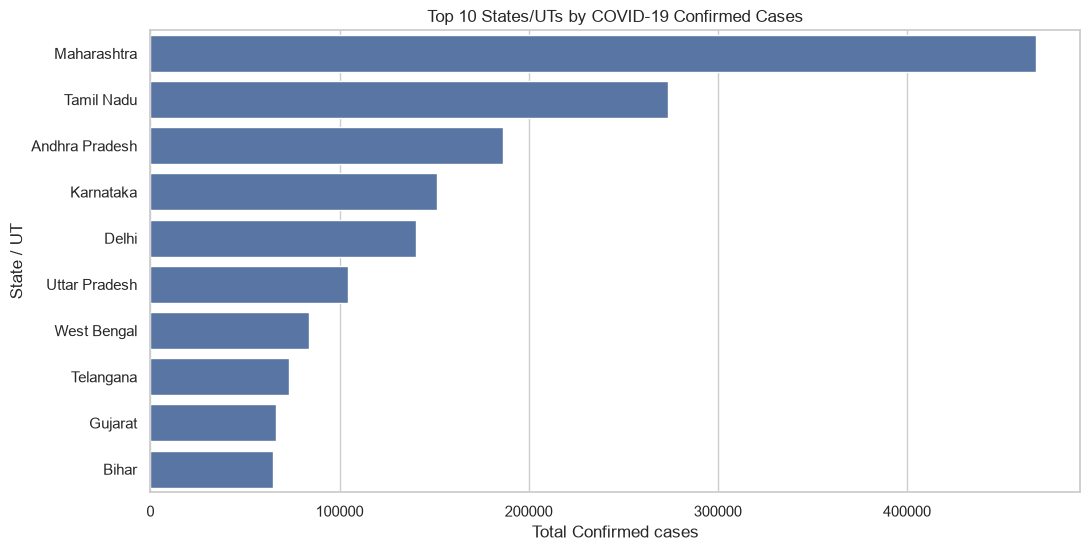

In [84]:
plt.figure(figsize = (12,6))

sns.barplot(
    data = top_cases.head(10),
    x = "Total Confirmed cases",
    y = "Name of State / UT"
)

plt.xlabel("Total Confirmed cases")
plt.ylabel("State / UT")
plt.title("Top 10 States/UTs by COVID-19 Confirmed Cases")

plt.show()

In [85]:
top_deaths = latest_data.sort_values(
    "Death",
    ascending = False
)

In [86]:
top_deaths[
    [
        "Name of State / UT",
        "Death",
        "Total Confirmed cases"
    ]
].head(10)

,Name of State / UT,Death,Total Confirmed cases
4676,Maharashtra,16476.0,468265.0
4686,Tamil Nadu,4461.0,273460.0
4665,Delhi,4044.0,140232.0
4672,Karnataka,2804.0,151449.0
4667,Gujarat,2556.0,66669.0
4689,Uttar Pradesh,1857.0,104388.0
4691,West Bengal,1846.0,83800.0
4658,Andhra Pradesh,1681.0,186461.0
4675,Madhya Pradesh,929.0,35734.0
4684,Rajasthan,745.0,47272.0


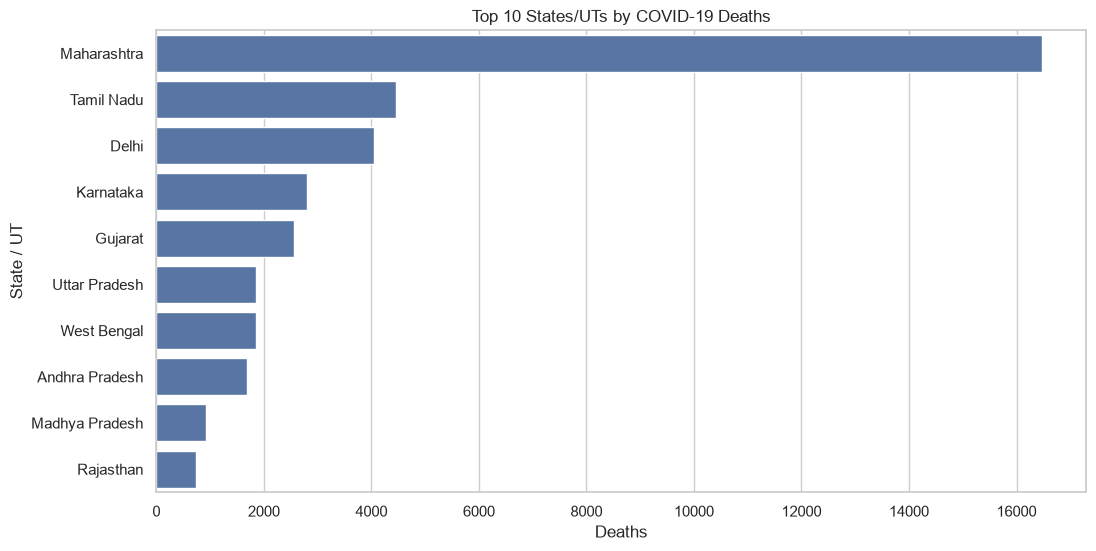

In [87]:
plt.figure(figsize = (12,6))

sns.barplot(
    data = top_deaths.head(10),
    x = "Death",
    y = "Name of State / UT"
)

plt.xlabel("Deaths")
plt.ylabel("State / UT")
plt.title("Top 10 States/UTs by COVID-19 Deaths")

plt.show()

In [88]:
latest_data["Active_Cases"] = (
    latest_data["Total Confirmed cases"] - latest_data["Death"] - latest_data["Cured/Discharged/Migrated"]
)

In [90]:
latest_data[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Death",
        "Cured/Discharged/Migrated",
        "Active_Cases"
    ]
].head()

,Name of State / UT,Total Confirmed cases,Death,Cured/Discharged/Migrated,Active_Cases
4657,Andaman and Nicobar Islands,1027.0,14.0,326.0,687.0
4658,Andhra Pradesh,186461.0,1681.0,104354.0,80426.0
4659,Arunachal Pradesh,1855.0,3.0,1210.0,642.0
4660,Assam,50445.0,121.0,35892.0,14432.0
4661,Bihar,64770.0,355.0,42414.0,22001.0


In [91]:
active_cases = latest_data.sort_values(
    "Active_Cases",
    ascending = False
)

active_cases[
    ["Name of State / UT","Active_Cases"]
].head(10)

,Name of State / UT,Active_Cases
4676,Maharashtra,146268.0
4658,Andhra Pradesh,80426.0
4672,Karnataka,73966.0
4686,Tamil Nadu,54184.0
4689,Uttar Pradesh,41973.0
4691,West Bengal,22992.0
4661,Bihar,22001.0
4687,Telangana,20358.0
4667,Gujarat,14680.0
4660,Assam,14432.0


In [92]:
latest_data["CFR"] = np.where(
    latest_data["Total Confirmed cases"] > 0,
    (
        latest_data["Death"] / latest_data["Total Confirmed cases"]
    ) * 100,
    np.nan
)

In [93]:
latest_data[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Death",
        "CFR"
    ]
].sort_values(
    "CFR",
    ascending = False
).head(10)

,Name of State / UT,Total Confirmed cases,Death,CFR
4667,Gujarat,66669.0,2556.0,3.833866
4676,Maharashtra,468265.0,16476.0,3.518520
4665,Delhi,140232.0,4044.0,2.883793
4675,Madhya Pradesh,35734.0,929.0,2.599765
4683,Punjab,19856.0,491.0,2.472804
4691,West Bengal,83800.0,1846.0,2.202864
4670,Jammu and Kashmir,22955.0,426.0,1.855805
4672,Karnataka,151449.0,2804.0,1.851448
4689,Uttar Pradesh,104388.0,1857.0,1.778940
4686,Tamil Nadu,273460.0,4461.0,1.631317


In [94]:
latest_data["Recovery_Rate"] = np.where(
    latest_data["Total Confirmed cases"] > 0,
    (
        latest_data["Cured/Discharged/Migrated"] / latest_data["Total Confirmed cases"]
    ) * 100,
    np.nan
)

In [96]:
latest_data[
    [
        "Name of State / UT",
        "Recovery_Rate"
    ]
].sort_values(
    "Recovery_Rate",
    ascending = False
).head(10)

,Name of State / UT,Recovery_Rate
4665,Delhi,89.933824
4668,Haryana,82.909619
4686,Tamil Nadu,78.554450
4663,Chhattisgarh,75.631786
4667,Gujarat,74.146905
4674,Ladakh,73.115578
4675,Madhya Pradesh,72.938938
4684,Rajasthan,71.604755
4687,Telangana,71.325120
4666,Goa,71.224572


In [97]:
state_analysis = latest_data[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Death",
        "Cured/Discharged/Migrated",
        "Active_Cases",
        "CFR",
        "Recovery_Rate"
    ]
].sort_values(
    "Total Confirmed cases",
    ascending = False
)

state_analysis.head(10)

,Name of State / UT,Total Confirmed cases,Death,Cured/Discharged/Migrated,Active_Cases,CFR,Recovery_Rate
4676,Maharashtra,468265.0,16476.0,305521.0,146268.0,3.518520,65.245320
4686,Tamil Nadu,273460.0,4461.0,214815.0,54184.0,1.631317,78.554450
4658,Andhra Pradesh,186461.0,1681.0,104354.0,80426.0,0.901529,55.965591
4672,Karnataka,151449.0,2804.0,74679.0,73966.0,1.851448,49.309669
4665,Delhi,140232.0,4044.0,126116.0,10072.0,2.883793,89.933824
4689,Uttar Pradesh,104388.0,1857.0,60558.0,41973.0,1.778940,58.012415
4691,West Bengal,83800.0,1846.0,58962.0,22992.0,2.202864,70.360382
4687,Telangana,73050.0,589.0,52103.0,20358.0,0.806297,71.325120
4667,Gujarat,66669.0,2556.0,49433.0,14680.0,3.833866,74.146905
4661,Bihar,64770.0,355.0,42414.0,22001.0,0.548093,65.484020


In [98]:
df[[
    "Name of State / UT",
    "Latitude",
    "Longitude"
]].head(10)

,Name of State / UT,Latitude,Longitude
0,Kerala,10.8505,76.2711
1,Kerala,10.8505,76.2711
2,Kerala,10.8505,76.2711
3,Kerala,10.8505,76.2711
4,Kerala,10.8505,76.2711
5,Kerala,10.8505,76.2711
6,Kerala,10.8505,76.2711
7,Kerala,10.8505,76.2711
8,Kerala,10.8505,76.2711
9,Kerala,10.8505,76.2711


In [99]:
df[["Latitude","Longitude"]].describe()

,Latitude,Longitude
count,4692.000000,4692.000000
mean,23.185327,81.451837
std,6.635913,6.959475
min,0.000000,0.000000
25%,18.112400,76.271100
50%,23.940800,79.019300
75%,28.218000,85.313100
max,34.299600,94.727800


In [100]:
df[["Latitude","Longitude"]].isnull().sum()

Latitude     0
Longitude    0
dtype: int64

In [102]:
latest_date = df["Date"].max()

latest_data = df[
    df["Date"] == latest_date
].copy()

In [103]:
latest_data.shape

(35, 14)

In [104]:
latest_data[[
    "Name of State / UT",
    "Latitude",
    "Longitude",
    "Total Confirmed cases"
]].head()

,Name of State / UT,Latitude,Longitude,Total Confirmed cases
4657,Andaman and Nicobar Islands,11.7401,92.6586,1027.0
4658,Andhra Pradesh,15.9129,79.7400,186461.0
4659,Arunachal Pradesh,28.2180,94.7278,1855.0
4660,Assam,26.2006,92.9376,50445.0
4661,Bihar,25.0961,85.3131,64770.0


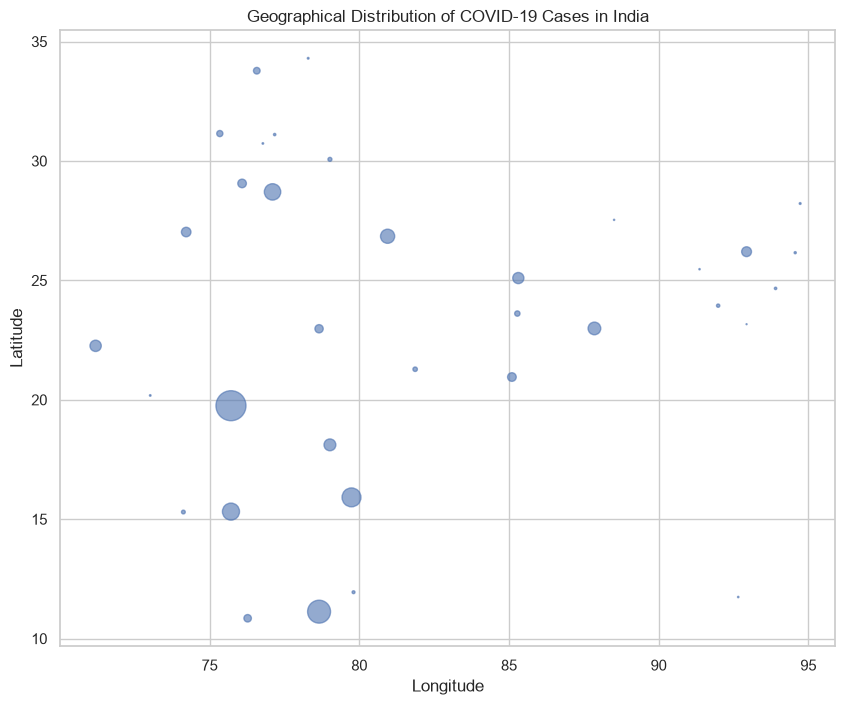

In [106]:
plt.figure(figsize = (10,8))

plt.scatter(
    latest_data["Longitude"],
    latest_data["Latitude"],
    s = latest_data["Total Confirmed cases"] / 1000,
    alpha = 0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of COVID-19 Cases in India")

plt.show()

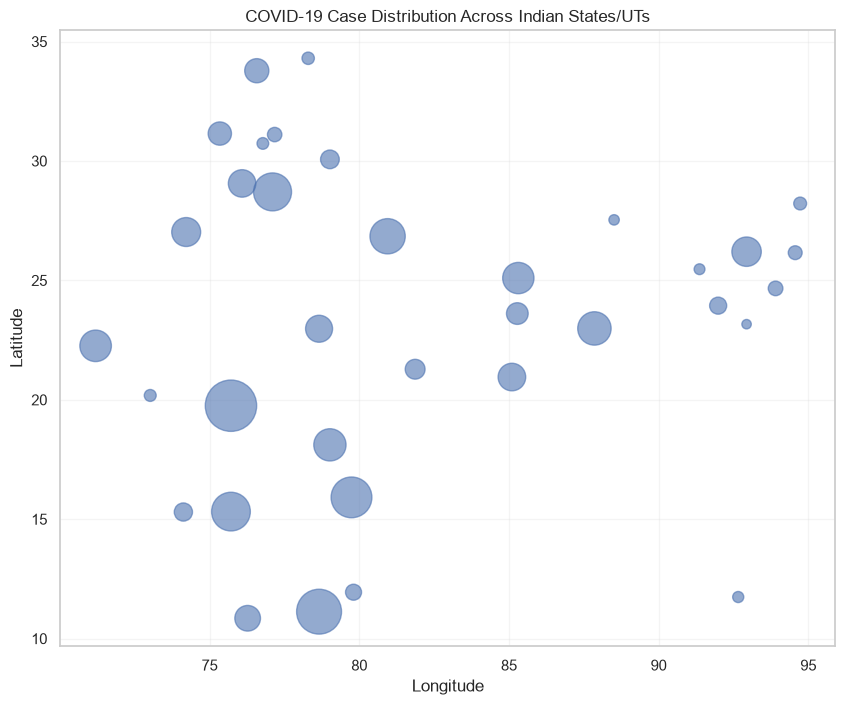

In [108]:
plt.figure(figsize = (10,8))

sizes = np.sqrt(
    latest_data["Total Confirmed cases"]
) * 2

plt.scatter(
    latest_data["Longitude"],
    latest_data["Latitude"],
    s = sizes,
    alpha = 0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("COVID-19 Case Distribution Across Indian States/UTs")

plt.grid(alpha = 0.2)

plt.show()

AttributeError: module 'matplotlib.pyplot' has no attribute 'ylabe'

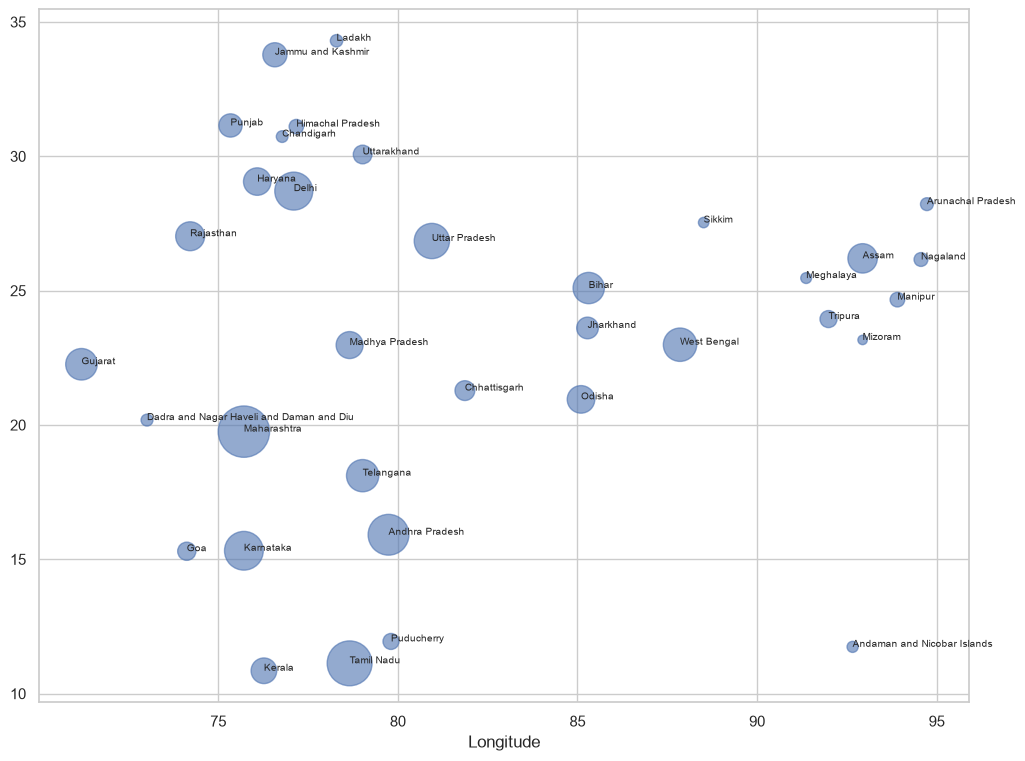

In [109]:
plt.figure(figsize = (12,9))

plt.scatter(
    latest_data["Longitude"],
    latest_data["Latitude"],
    s = np.sqrt(latest_data["Total Confirmed cases"]) * 2,
    alpha = 0.6
)

for _, row in latest_data.iterrows():
    plt.text(
        row["Longitude"],
        row["Latitude"],
        row["Name of State / UT"],
        fontsize = 7
    )

plt.xlabel("Longitude")
plt.ylabe("Latitude")
plt.title("COVID-19 Cases by Indian State/UT")

plt.show()

In [111]:
latest_data["Case_Level"] = pd.cut(
    latest_data["Total Confirmed cases"],
    bins = 3,
    labels = [
        "Low",
        "Medium",
        "High"
    ]
)

In [113]:
latest_data[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Case_Level"
    ]
].sort_values(
    "Total Confirmed cases",
    ascending = False
)

,Name of State / UT,Total Confirmed cases,Case_Level
4676,Maharashtra,468265.0,High
4686,Tamil Nadu,273460.0,Medium
4658,Andhra Pradesh,186461.0,Medium
4672,Karnataka,151449.0,Low
4665,Delhi,140232.0,Low
4689,Uttar Pradesh,104388.0,Low
4691,West Bengal,83800.0,Low
4687,Telangana,73050.0,Low
4667,Gujarat,66669.0,Low
4661,Bihar,64770.0,Low


In [114]:
numeric_columns = [
    "Total Confirmed cases",
    "Death",
    "Cured/Discharged/Migrated",
    "New cases",
    "New deaths",
    "New recovered"
]

In [115]:
correlation = latest_data[
    numeric_columns
].corr()

correlation

,Total Confirmed cases,Death,Cured/Discharged/Migrated,New cases,New deaths,New recovered
Total Confirmed cases,1.000000,0.927228,0.987745,0.885145,NaN,0.832304
Death,0.927228,1.000000,0.915041,0.723115,NaN,0.603068
Cured/Discharged/Migrated,0.987745,0.915041,1.000000,0.821110,NaN,0.778745
New cases,0.885145,0.723115,0.821110,1.000000,NaN,0.965807
New deaths,NaN,NaN,NaN,NaN,NaN,NaN
New recovered,0.832304,0.603068,0.778745,0.965807,NaN,1.000000


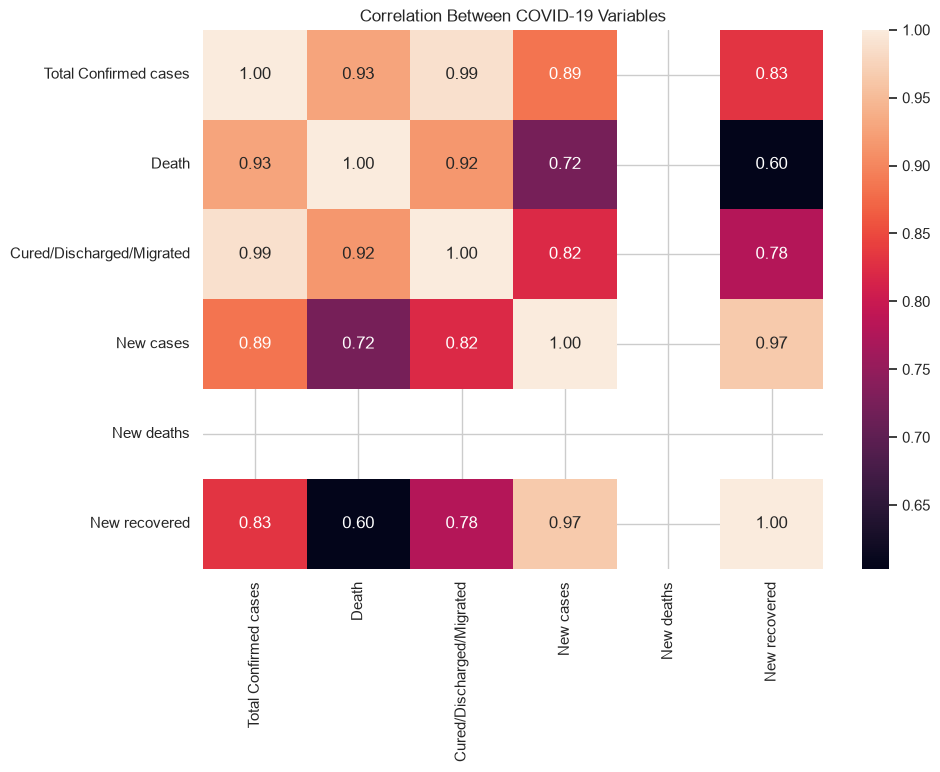

In [117]:
plt.figure(figsize = (10,7))

sns.heatmap(
    correlation,
    annot = True,
    fmt = ".2f"
)

plt.title("Correlation Between COVID-19 Variables")

plt.show()

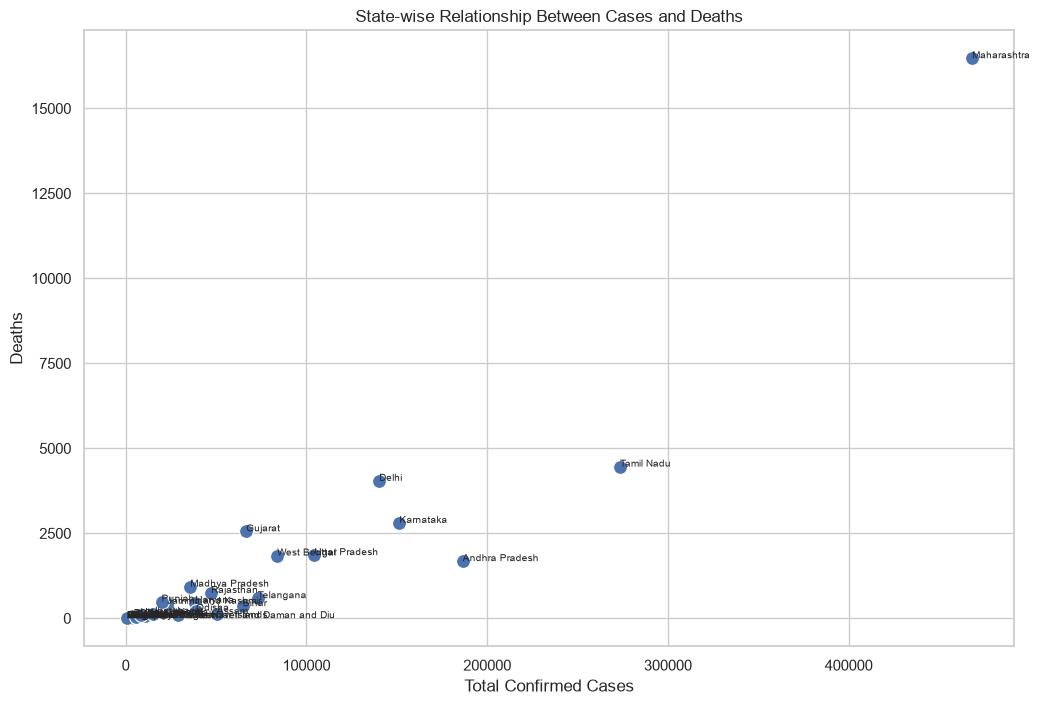

In [120]:
plt.figure(figsize = (12,8))

sns.scatterplot(
    data = latest_data,
    x = "Total Confirmed cases",
    y = "Death",
    s = 100
)

for _, row in latest_data.iterrows():
    plt.text(
        row["Total Confirmed cases"],
        row["Death"],
        row["Name of State / UT"],
        fontsize = 7
    )

plt.xlabel("Total Confirmed Cases")
plt.ylabel("Deaths")
plt.title("State-wise Relationship Between Cases and Deaths")

plt.show()

In [121]:
latest_data["Active_Cases"] = (
    latest_data["Total Confirmed cases"]
    - latest_data["Death"]
    -latest_data["Cured/Discharged/Migrated"]
)

In [122]:
latest_data["CFR"] = np.where(
    latest_data["Total Confirmed cases"] > 0,
    (
        latest_data["Death"] /
        latest_data["Total Confirmed cases"]
    ) * 100,
    np.nan
)
    

In [123]:
latest_data["Recovery_Rate"] = np.where(
    latest_data["Total Confirmed cases"] > 0,
    (
        latest_data["Cured/Discharged/Migrated"] /
        latest_data["Total Confirmed cases"]
    ) * 100,
    np.nan
)

In [125]:
state_analysis = latest_data[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Death",
        "Cured/Discharged/Migrated",
        "Active_Cases",
        "CFR",
        "Recovery_Rate",
        "Latitude",
        "Longitude"
    ]
].sort_values(
    "Total Confirmed cases",
    ascending = False
)

In [126]:
state_analysis.head(15)

,Name of State / UT,Total Confirmed cases,Death,Cured/Discharged/Migrated,Active_Cases,CFR,Recovery_Rate,Latitude,Longitude
4676,Maharashtra,468265.0,16476.0,305521.0,146268.0,3.518520,65.245320,19.7515,75.7139
4686,Tamil Nadu,273460.0,4461.0,214815.0,54184.0,1.631317,78.554450,11.1271,78.6569
4658,Andhra Pradesh,186461.0,1681.0,104354.0,80426.0,0.901529,55.965591,15.9129,79.7400
4672,Karnataka,151449.0,2804.0,74679.0,73966.0,1.851448,49.309669,15.3173,75.7139
4665,Delhi,140232.0,4044.0,126116.0,10072.0,2.883793,89.933824,28.7041,77.1025
4689,Uttar Pradesh,104388.0,1857.0,60558.0,41973.0,1.778940,58.012415,26.8467,80.9462
4691,West Bengal,83800.0,1846.0,58962.0,22992.0,2.202864,70.360382,22.9868,87.8550
4687,Telangana,73050.0,589.0,52103.0,20358.0,0.806297,71.325120,18.1124,79.0193
4667,Gujarat,66669.0,2556.0,49433.0,14680.0,3.833866,74.146905,22.2587,71.1924
4661,Bihar,64770.0,355.0,42414.0,22001.0,0.548093,65.484020,25.0961,85.3131


In [127]:
top_10_cases = state_analysis.head(10)

In [128]:
top_10_deaths = state_analysis.sort_values(
    "Death",
    ascending = False
).head(10)

In [129]:
top_10_active = state_analysis.sort_values(
    "Active_Cases",
    ascending = False
).head(10)

In [130]:
top_10_cfr = state_analysis.sort_values(
    "CFR",
    ascending = False
).head(10)

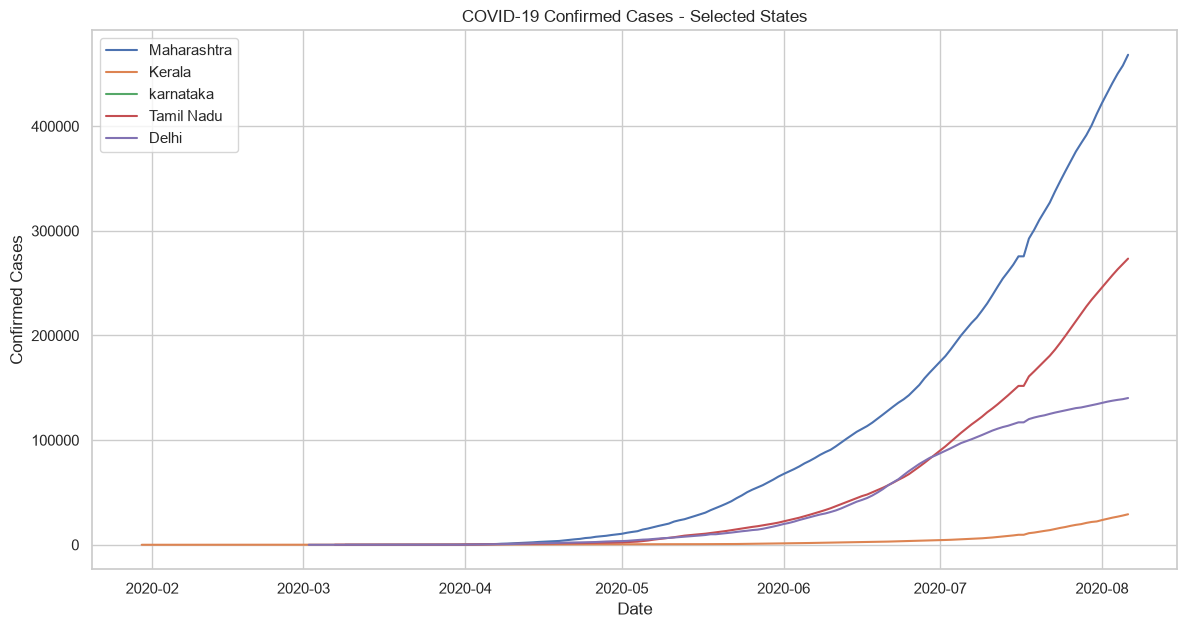

In [133]:
states = [
    "Maharashtra",
    "Kerala",
    "karnataka",
    "Tamil Nadu",
    "Delhi"
]

plt.figure(figsize = (14,7))

for state in states:

    state_data = df[
        df["Name of State / UT"] == state
    ].sort_values("Date")
    plt.plot(
        state_data["Date"],
        state_data["Total Confirmed cases"],
        label = state
    )

plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.title("COVID-19 Confirmed Cases - Selected States")
plt.legend()

plt.show()

In [134]:
state_analysis.describe()

,Total Confirmed cases,Death,Cured/Discharged/Migrated,Active_Cases,CFR,Recovery_Rate,Latitude,Longitude
count,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000
mean,56129.600000,1162.828571,37952.457143,17014.314286,1.192257,62.314655,23.357097,82.070229
std,94624.131873,2905.889734,64451.418650,30019.320692,0.989969,14.286907,6.463139,7.255625
min,537.000000,0.000000,286.000000,251.000000,0.000000,27.421938,10.850500,71.192400
25%,2707.000000,14.000000,1486.000000,1182.000000,0.459904,57.155814,19.966200,76.423650
50%,19856.000000,121.000000,12943.000000,6422.000000,0.901529,65.245320,23.940800,79.019300
75%,65719.500000,837.000000,45923.500000,14556.000000,1.705129,71.274846,27.875500,88.183600
max,468265.000000,16476.000000,305521.000000,146268.000000,3.833866,89.933824,34.299600,94.727800


In [136]:
mean_cases = state_analysis["Total Confirmed cases"].mean()
median_cases = state_analysis["Total Confirmed cases"].median()

print("Mean:",mean_cases)
print("Meadian:",median_cases)

Mean: 56129.6
Meadian: 19856.0


In [137]:
mean_deaths = state_analysis["Death"].mean()
median_deaths = state_analysis["Death"].median()

print("Mean:",mean_deaths)
print("Meadian:",median_deaths)

Mean: 1162.8285714285714
Meadian: 121.0


In [138]:
mean_cfr = state_analysis["CFR"].mean()
median_cfr = state_analysis["CFR"].median()

print("Mean:",mean_cfr)
print("Meadian:",median_cfr)

Mean: 1.1922568611369957
Meadian: 0.9015290060656116


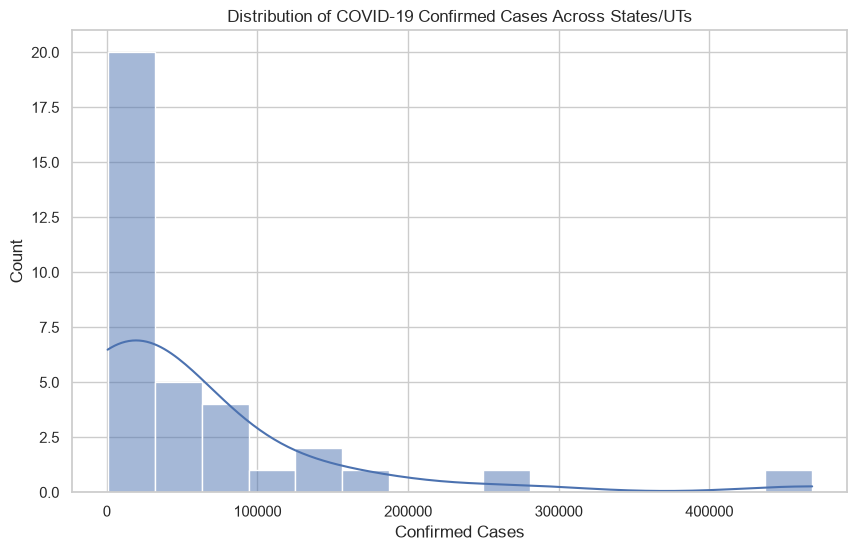

In [140]:
plt.figure(figsize =(10,6))

sns.histplot(
    state_analysis["Total Confirmed cases"],
    bins = 15,
    kde = True
)

plt.xlabel("Confirmed Cases")
plt.title("Distribution of COVID-19 Confirmed Cases Across States/UTs")

plt.show()


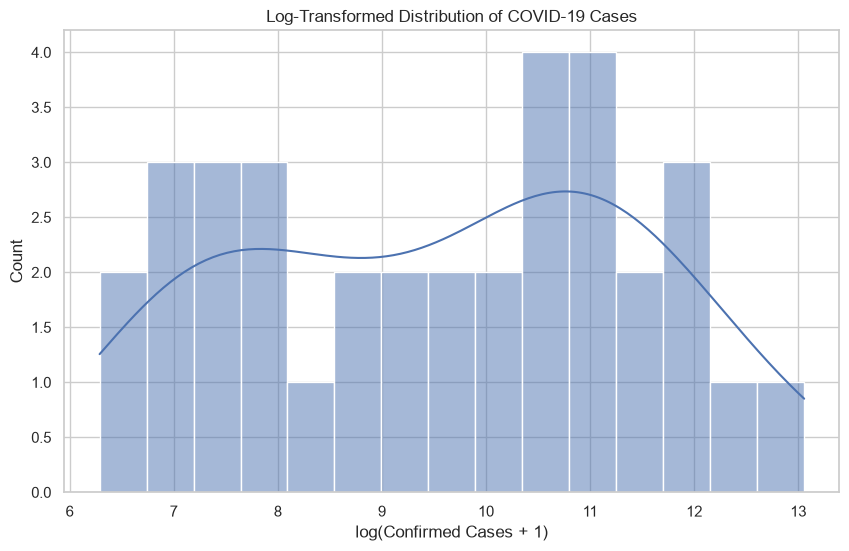

In [141]:
plt.figure(figsize = (10,6))

sns.histplot(
    np.log1p(state_analysis["Total Confirmed cases"]),
    bins = 15,
    kde = True
)

plt.xlabel("log(Confirmed Cases + 1)")
plt.title("Log-Transformed Distribution of COVID-19 Cases")

plt.show()
    

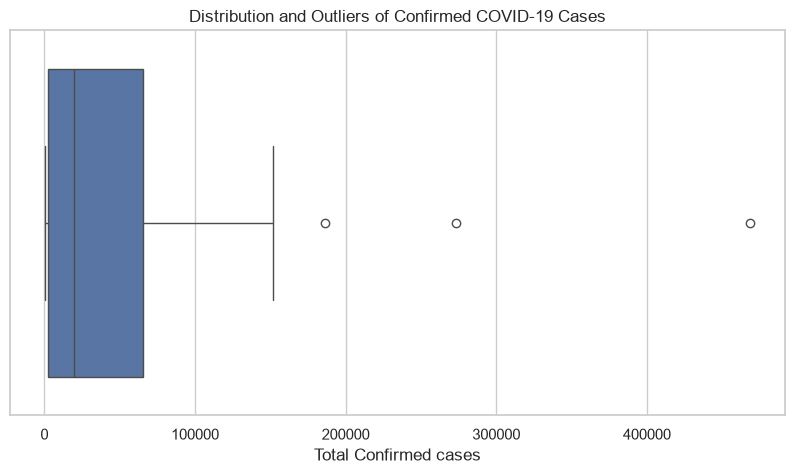

In [143]:
plt.figure(figsize = (10,5))

sns.boxplot(
    x = state_analysis["Total Confirmed cases"]
)

plt.title("Distribution and Outliers of Confirmed COVID-19 Cases")

plt.show()

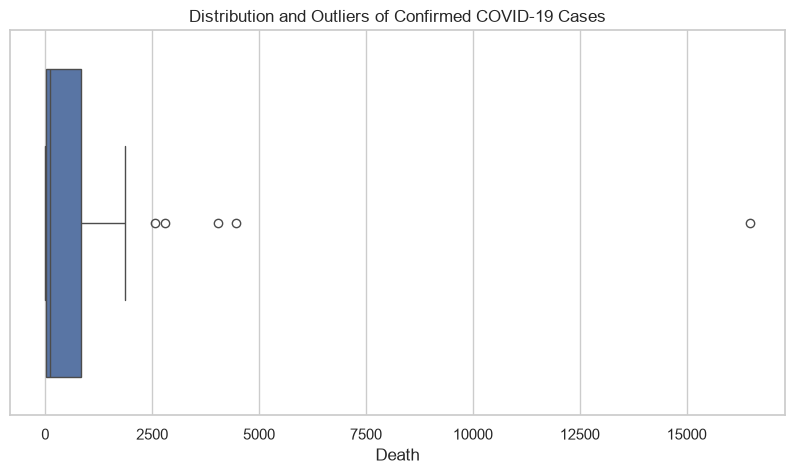

In [144]:
plt.figure(figsize = (10,5))

sns.boxplot(
    x = state_analysis["Death"]
)

plt.title("Distribution and Outliers of Confirmed COVID-19 Cases")

plt.show()

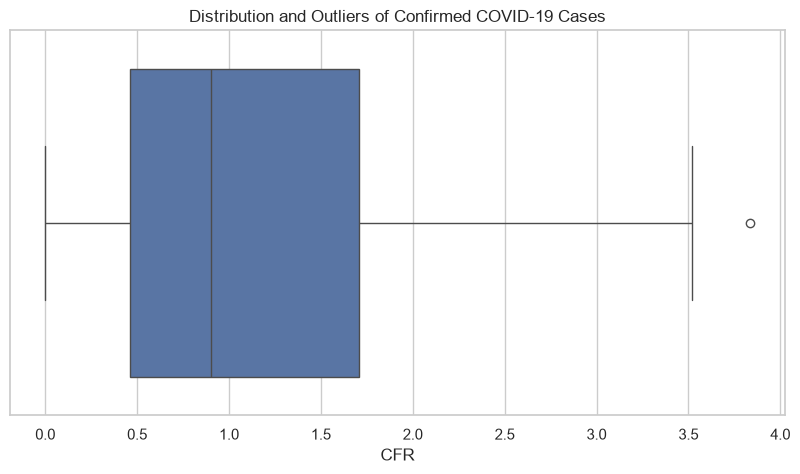

In [145]:
plt.figure(figsize = (10,5))

sns.boxplot(
    x = state_analysis["CFR"]
)

plt.title("Distribution and Outliers of Confirmed COVID-19 Cases")

plt.show()

In [146]:
correation = state_analysis[
    [
        "Total Confirmed cases",
        "Death",
        "Cured/Discharged/Migrated",
        "Active_Cases",
        "CFR",
        "Recovery_Rate"
    ]
].corr()

correlation

,Total Confirmed cases,Death,Cured/Discharged/Migrated,New cases,New deaths,New recovered
Total Confirmed cases,1.000000,0.927228,0.987745,0.885145,NaN,0.832304
Death,0.927228,1.000000,0.915041,0.723115,NaN,0.603068
Cured/Discharged/Migrated,0.987745,0.915041,1.000000,0.821110,NaN,0.778745
New cases,0.885145,0.723115,0.821110,1.000000,NaN,0.965807
New deaths,NaN,NaN,NaN,NaN,NaN,NaN
New recovered,0.832304,0.603068,0.778745,0.965807,NaN,1.000000


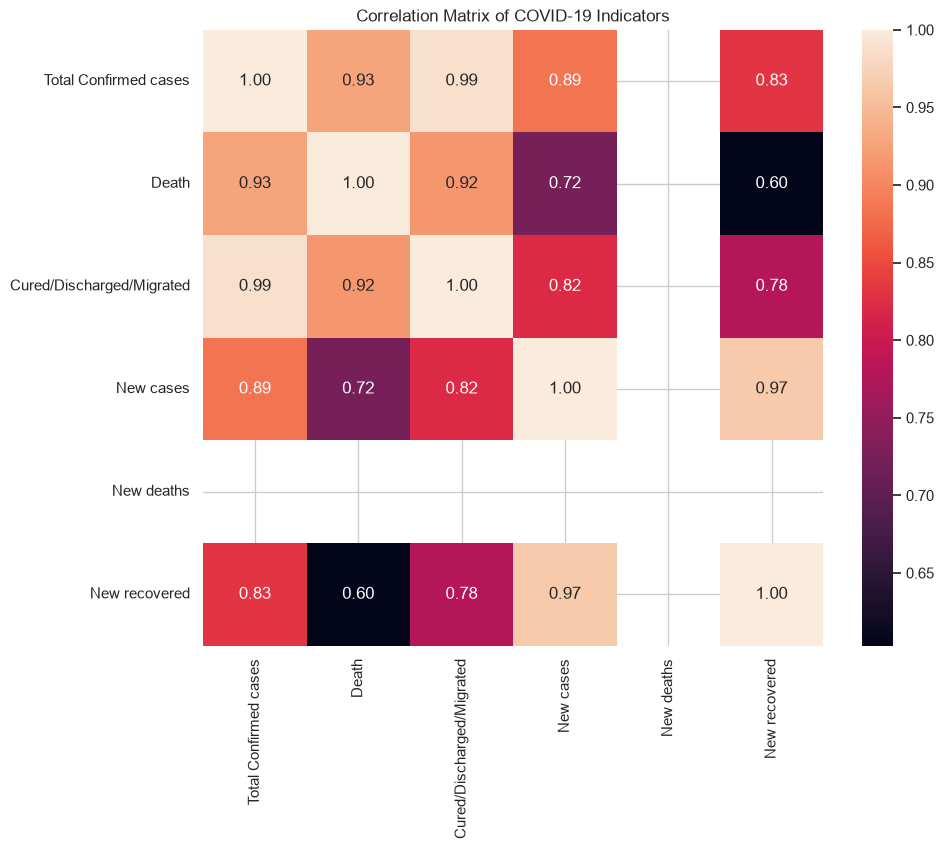

In [147]:
plt.figure(figsize = (10,8))

sns.heatmap(
    correlation,
    annot = True,
    fmt = ".2f"
)

plt.title("Correlation Matrix of COVID-19 Indicators")

plt.show()

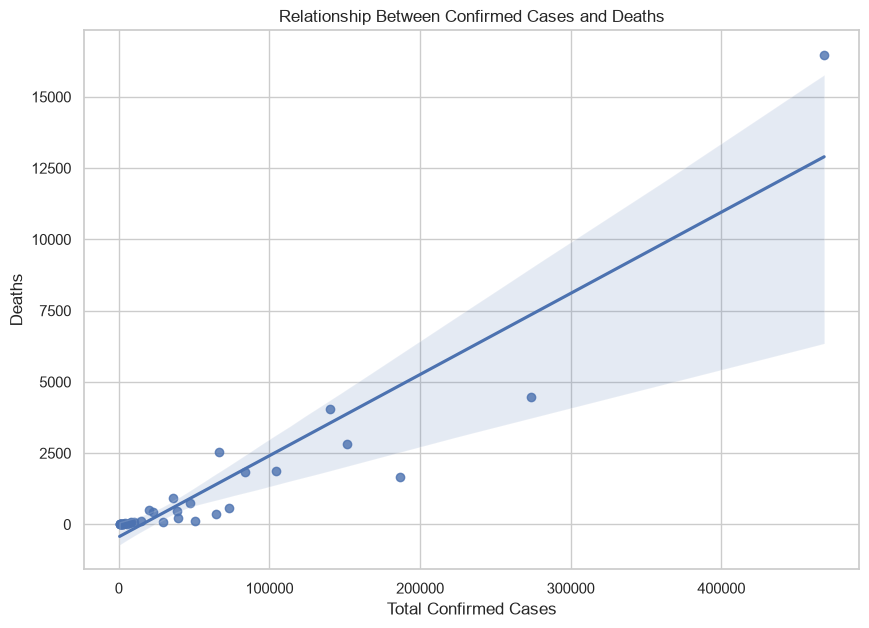

In [148]:
plt.figure(figsize = (10,7))

sns.regplot(
    data = state_analysis,
    x = "Total Confirmed cases",
    y = "Death"
)

plt.xlabel("Total Confirmed Cases")
plt.ylabel("Deaths")
plt.title("Relationship Between Confirmed Cases and Deaths")

plt.show()

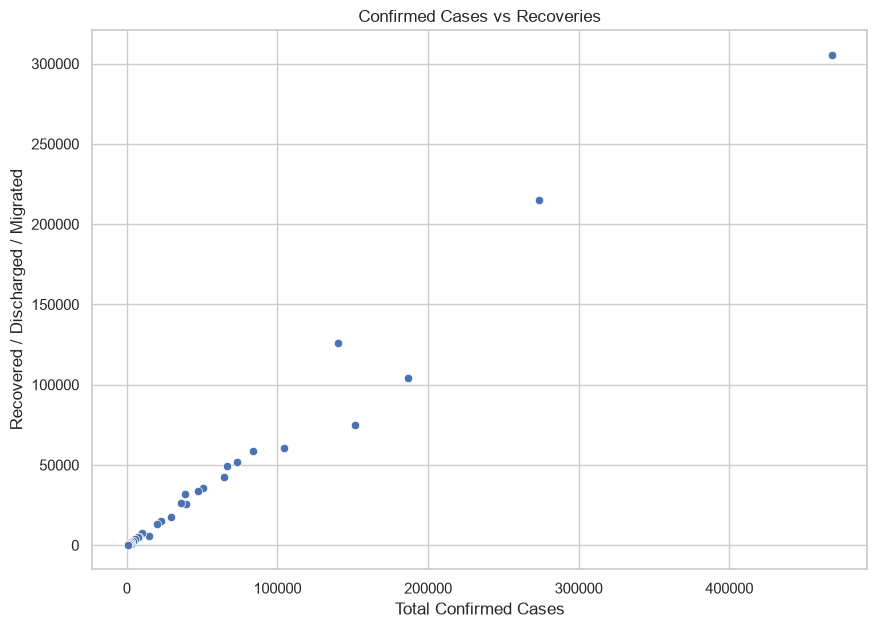

In [149]:
plt.figure(figsize =(10,7))

sns.scatterplot(
    data = state_analysis,
    x = "Total Confirmed cases",
    y = "Cured/Discharged/Migrated"
)

plt.xlabel("Total Confirmed Cases")
plt.ylabel("Recovered / Discharged / Migrated")
plt.title("Confirmed Cases vs Recoveries")

plt.show()

In [150]:
corr_pairs = (
    correlation.unstack().sort_values(ascending = False)
)
corr_pairs

Total Confirmed cases      Total Confirmed cases        1.000000
Death                      Death                        1.000000
New recovered              New recovered                1.000000
New cases                  New cases                    1.000000
Cured/Discharged/Migrated  Cured/Discharged/Migrated    1.000000
                           Total Confirmed cases        0.987745
Total Confirmed cases      Cured/Discharged/Migrated    0.987745
New recovered              New cases                    0.965807
New cases                  New recovered                0.965807
Total Confirmed cases      Death                        0.927228
Death                      Total Confirmed cases        0.927228
Cured/Discharged/Migrated  Death                        0.915041
Death                      Cured/Discharged/Migrated    0.915041
Total Confirmed cases      New cases                    0.885145
New cases                  Total Confirmed cases        0.885145
New recovered            

In [152]:
cases_death_corr = state_analysis[
    [
        "Total Confirmed cases",
        "Death"
    ]
].corr().iloc[0,1]

print(
    "Correlation between confirmed cases and deaths :",cases_death_corr)


Correlation between confirmed cases and deaths : 0.927228170267613


In [154]:
state_analysis[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Death",
        "CFR"
    ]
].sort_values(
    "CFR",
    ascending = False
).head(10)

,Name of State / UT,Total Confirmed cases,Death,CFR
4667,Gujarat,66669.0,2556.0,3.833866
4676,Maharashtra,468265.0,16476.0,3.518520
4665,Delhi,140232.0,4044.0,2.883793
4675,Madhya Pradesh,35734.0,929.0,2.599765
4683,Punjab,19856.0,491.0,2.472804
4691,West Bengal,83800.0,1846.0,2.202864
4670,Jammu and Kashmir,22955.0,426.0,1.855805
4672,Karnataka,151449.0,2804.0,1.851448
4689,Uttar Pradesh,104388.0,1857.0,1.778940
4686,Tamil Nadu,273460.0,4461.0,1.631317


In [155]:
state_analysis[
    [
        "Name of State / UT",
        "Total Confirmed cases",
        "Cured/Discharged/Migrated",
        "Recovery_Rate"
    ]
].sort_values(
    "Recovery_Rate",
    ascending = False
).head(10)

,Name of State / UT,Total Confirmed cases,Cured/Discharged/Migrated,Recovery_Rate
4665,Delhi,140232.0,126116.0,89.933824
4668,Haryana,38548.0,31960.0,82.909619
4686,Tamil Nadu,273460.0,214815.0,78.554450
4663,Chhattisgarh,10407.0,7871.0,75.631786
4667,Gujarat,66669.0,49433.0,74.146905
4674,Ladakh,1592.0,1164.0,73.115578
4675,Madhya Pradesh,35734.0,26064.0,72.938938
4684,Rajasthan,47272.0,33849.0,71.604755
4687,Telangana,73050.0,52103.0,71.325120
4666,Goa,7423.0,5287.0,71.224572


# Key Findings & Insights

Based on the analysis performed on the COVID-19 dataset , several important patterns were identified.

## 1. Time-Series Findings
The daily case analysis and 7-Day moving average were used to understand the temporal pattern of COVID-19 cases.

## 2. State-wise Findings
States/UTs showed considerable variation in confirmed cases, deaths, recoveries and active cases.

## 3. Mortality Findings
The relationship between confirmed cases and deaths was examined using correlation and regression analysis.

## 4. Recovery Findings
Recovery rates varied across states/UTs, indicating differences in the observed COVID-19 outcomes.

## 5. Statistical Findings
Descriptive statistics, distribution, boxplots and correlation analysis were used to understand variation and outliers in the dataset.

# Limitations

1. The dataset represents reported COVID-19 cases and therefore may not
   represent the complete number of infections.

2. Differences in testing, reporting and data collection across states/UTs
   can affect comparisons.

3. Correlation between variables does not establish causation.

4. Case Fatality Rate (CFR) can be influenced by factors such as testing,
   reporting delays and the number of detected cases.

5. The analysis is primarily descriptive and does not establish causal
   relationships.

6. Geographic analysis is based on state/UT latitude and longitude and
   therefore does not represent the exact geographical distribution of
   individual cases.

# Conclusion

This project analyzed COVID-19 data across Indian states and union
territories using Python and several data-analysis and visualization
techniques.

The analysis included data cleaning, feature engineering, exploratory data
analysis, time-series analysis, state-wise comparison, geographic analysis,
statistical analysis and correlation analysis.

The time-series analysis helped examine how reported COVID-19 cases changed
over time, while the state-wise analysis revealed substantial variation in
confirmed cases, deaths, recoveries and active cases among different
states and union territories.

Statistical analysis was used to understand the distribution of COVID-19
indicators and identify variation and potential outliers. Correlation and
regression analysis were also used to examine relationships between
confirmed cases, deaths and recoveries.

Overall, the project demonstrates how Python libraries such as Pandas,
NumPy, Matplotlib and Seaborn can be used to transform a raw healthcare
dataset into meaningful analytical insights and visualizations.

The analysis should be interpreted as descriptive rather than causal.
Differences in testing, reporting, population characteristics and other
factors can influence the observed values.

This project provided practical experience in data preprocessing,
exploratory data analysis, statistical analysis, visualization and
data-driven interpretation, forming a foundation for more advanced
machine-learning and predictive analytics projects.

# Project Summary

### Dataset
COVID-19 data from Indian states and union territories

### Tools Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

### Analysis Performed
- Data Cleaning
- Feature Engineering
- Exploratory Data Analysis
- Time-Series Analysis
- Rolling Average Analysis
- Peak Analysis
- Outlier Detection
- State-wise Analysis
- Geographic Analysis
- Correlation Analysis
- Statistical Analysis
- Regression Visualization

### Key Outcomes
- Understanding temporal patterns
- Comparing COVID-19 outcomes across states/UTs
- Examining relationships between cases, deaths and recoveries
- Identifying distributions and outliers
- Creating analytical visualizations